# Домашнее задание 1. Рекомендации косметики
**Ромашкина Мария Михайловна**

Зависимости устанавливаются следующей ячейкой. Запускайте ноутбук из корня репозитория.


In [1]:
%pip install -q numpy==2.0.2 scipy==1.13.1 pandas==2.3.3 matplotlib==3.9.4 "jupyterlab>=4,<5"

You should consider upgrading via the '/Users/roromska/Documents/Codex/2026-10-16/1-top-10-github-100-000/work/venv/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


## 1. Загрузка и описание данных
Используем **eCommerce Events History in Cosmetics Shop**, REES46, октябрь 2019: [первоисточник](https://data.rees46.com/), [описание и загрузка](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop).

Одна строка — действие пользователя с товаром. `user_id` и `product_id` — идентификаторы; `event_time` — время UTC; `event_type` — просмотр, корзина, удаление из корзины или покупка; `category_id`/`category_code` — категория; `brand` — бренд; `price` — цена; `user_session` — сессия.

Рекомендуем 10 новых для пользователя товаров. Релевантный товар — тот, который пользователь добавил в корзину или купил в период оценки. Корзина означает интерес, но не гарантирует покупку; последующее удаление не отменяет релевантность по выбранному правилу.

Выполните все ячейки по порядку. Нужен Python 3.9–3.12, около 3 ГБ RAM. Данные автоматически скачиваются в `cache/`. Если загрузка не работает, положите туда `2019-Oct.csv` со страницы датасета.

In [2]:
import os

for name in ['OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS']:
    os.environ[name] = '1'

In [3]:
from pathlib import Path
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from models.item_knn import ItemKNN
from models.ials import ImplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_als import CustomTargetALS
from scipy import sparse

In [4]:
np.seterr(divide="raise", over="raise", invalid="raise")

TRAIN_END = pd.Timestamp('2019-10-21', tz='UTC')
VALID_END = pd.Timestamp('2019-10-26', tz='UTC')

EVENTS = ['view', 'cart', 'purchase', 'remove_from_cart']

In [5]:
SEED = 42
pd.set_option('display.max_colwidth', None)

In [6]:
path = Path('cache/2019-Oct.csv')

if not path.exists():
    path.parent.mkdir(exist_ok=True)
    url = 'https://www.kaggle.com/api/v1/datasets/download/mkechinov/ecommerce-events-history-in-cosmetics-shop/2019-Oct.csv'
    urllib.request.urlretrieve(url, 'cache/october.zip')

    with zipfile.ZipFile('cache/october.zip') as archive:
        archive.extract('2019-Oct.csv', 'cache')

In [7]:
raw = pd.read_csv(path)

stats = {'raw_rows': len(raw), 'raw_users': raw.user_id.nunique(),
         'raw_items': raw.product_id.nunique(), 'missing_fraction': raw.isna().mean().to_dict(),
         'event_counts_raw': raw.event_type.value_counts().to_dict(),
         'exact_duplicates': int(raw.duplicated().sum())}

In [8]:
raw = raw.drop_duplicates().copy()
raw.event_time = pd.to_datetime(raw.event_time, utc=True, errors='coerce')
raw = raw.dropna(subset=['user_id', 'product_id', 'event_time'])
raw = raw[raw.event_type.isin(EVENTS)].copy()


raw.loc[raw.price <= 0, 'price'] = np.nan
raw['brand'] = raw.brand.fillna('__unknown__')
raw['category_id'] = raw.category_id.fillna(-1).astype(str)

stats['clean_rows_before_selection'] = len(raw)

In [9]:
history = raw[raw.event_time < TRAIN_END]
popularity = history.groupby('product_id').user_id.nunique()
item_ids = np.sort(popularity.sort_values(ascending=False, kind='stable').head(3000).index)

activity = history[history.product_id.isin(item_ids)].groupby('user_id').product_id.nunique()
user_ids = np.sort(activity.sort_values(ascending=False, kind='stable').head(12000).index)

In [10]:
events = raw[raw.product_id.isin(item_ids) & raw.user_id.isin(user_ids)].copy()
events['u'] = np.searchsorted(user_ids, events.user_id)
events['i'] = np.searchsorted(item_ids, events.product_id)
events = events.sort_values(['event_time', 'u', 'i', 'event_type'], kind='stable').reset_index(drop=True)

In [11]:
stats.update(selected_rows=len(events), selected_users=len(user_ids), selected_items=len(item_ids),
             selected_unique_pairs=len(events[['u','i']].drop_duplicates()))

assert 100_000 <= len(events) <= 2_000_000
assert len(user_ids) >= 1000 and len(item_ids) >= 1000

stats['sparsity'] = 1 - stats['selected_unique_pairs'] / (len(user_ids)*len(item_ids))
shape = (len(user_ids), len(item_ids))

display(pd.Series({k: v for k, v in stats.items() if not isinstance(v, dict)}).to_frame('value'))

,value
raw_rows,4.102283e+06
raw_users,3.996640e+05
raw_items,4.189900e+04
exact_duplicates,2.131550e+05
clean_rows_before_selection,3.889128e+06
selected_rows,8.097720e+05
selected_users,1.200000e+04
selected_items,3.000000e+03
selected_unique_pairs,3.891890e+05
sparsity,9.891892e-01


## 2. EDA и подготовка
Удаляем полные дубликаты, строки без ID или времени и неизвестные типы событий. Повторные действия в разное время сохраняем. Неположительную цену считаем пропуском признака, а не причиной удаления события. Пропущенный бренд получает значение `__unknown__`.

Для воспроизводимой выборки только по периоду 1–20 октября выбираем 3000 товаров с наибольшим числом пользователей. Среди них выбираем 12000 пользователей с наибольшим числом разных товаров. Равенство разрешаем по возрастанию исходного ID. Эти множества фиксируем для всего месяца. Такой отбор позволяет обучить EASE на CPU, но смещает выборку к популярным товарам и активным пользователям.

In [12]:
display(pd.Series(stats['missing_fraction'], name='Доля пропусков до очистки'))
display(pd.Series(stats['event_counts_raw'], name='Исходные события'))

event_time       0.000000
event_type       0.000000
product_id       0.000000
category_id      0.000000
category_code    0.983551
brand            0.404473
price            0.000000
user_id          0.000000
user_session     0.000155
Name: Доля пропусков до очистки, dtype: float64

view                1862164
cart                1232385
remove_from_cart     762110
purchase             245624
Name: Исходные события, dtype: int64

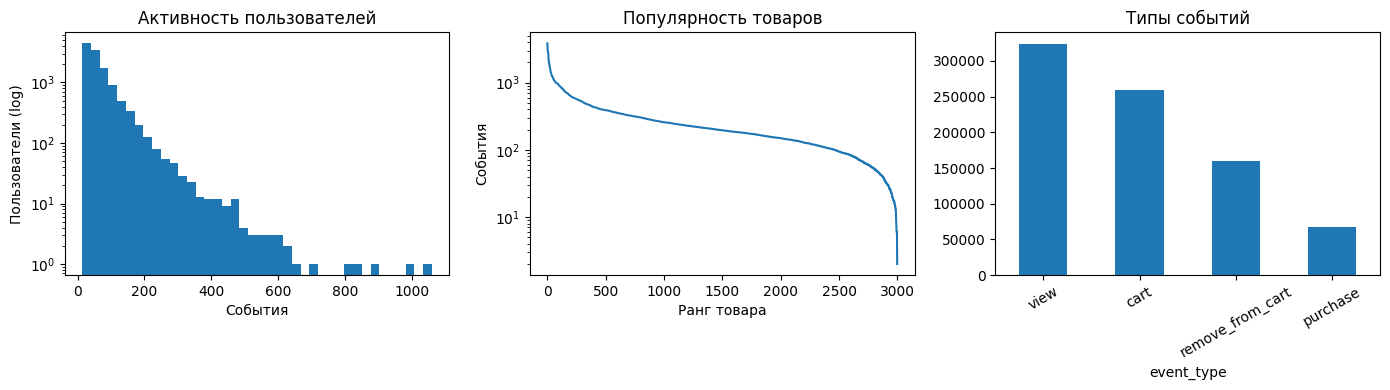

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(events.groupby('u').size(), bins=40, log=True)
axes[0].set(title='Активность пользователей', xlabel='События', ylabel='Пользователи (log)')

axes[1].plot(np.sort(events.groupby('i').size())[::-1])
axes[1].set(title='Популярность товаров', xlabel='Ранг товара', ylabel='События', yscale='log')

events.event_type.value_counts().plot.bar(ax=axes[2], title='Типы событий', rot=30)

plt.tight_layout()
plt.show()

In [14]:
train = events[events.event_time < TRAIN_END].copy()
validation = events[(events.event_time >= TRAIN_END) & (events.event_time < VALID_END)].copy()

In [15]:
display(pd.Series({
    'Категорий в train': train.category_id.nunique(),
    'Известных брендов': train.loc[train.brand != '__unknown__', 'brand'].nunique(),
    'Доля неизвестных брендов': (train.brand == '__unknown__').mean(),
    'Медианная цена': train.price.median(),
    'Разреженность': stats['sparsity']
}))

Категорий в train           276.000000
Известных брендов           102.000000
Доля неизвестных брендов      0.416480
Медианная цена                3.490000
Разреженность                 0.989189
dtype: float64

### Насколько заполнены признаки FM

Проверяем метаданные каждого товара в последнем доступном снимке train — именно такой снимок получает FM. Каждый товар учитывается один раз. График показывает, для какой доли каталога бренд, категория и цена действительно известны. Он помогает оценить доступность признаков, но сам по себе не измеряет их вклад в качество FM.

In [16]:
snapshot = train.sort_values('event_time', kind='stable').drop_duplicates('i', keep='last')

coverage = pd.Series({
    'Категория': snapshot.category_id.ne('-1').mean(),
    'Бренд': snapshot.brand.ne('__unknown__').mean(),
    'Цена': snapshot.price.notna().mean()
}) * 100

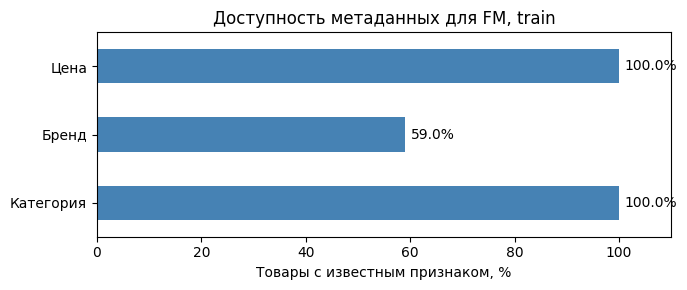

In [17]:
ax = coverage.plot.barh(figsize=(7, 3), color='steelblue')
ax.set(xlim=(0, 110), xlabel='Товары с известным признаком, %', title='Доступность метаданных для FM, train')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=4)

plt.tight_layout()
plt.show()

## 3. Протокол оценки
Глобальное временное разбиение UTC: **train — 1–20 октября, validation — 21–25, test — 26–31**. После подбора переобучаем модели на train + validation. Все признаки берём только до соответствующей границы рекомендации.

Кандидаты — весь выбранный каталог минус все ранее наблюдавшиеся пользователем товары, включая удаления из корзины. Релевантные ответы тоже очищаем от уже известных товаров. Новых пользователей и товары вне зафиксированной выборки исключаем. Оцениваем всех пользователей с хотя бы одним новым релевантным товаром; списки пользователей и кандидатов одинаковы для пяти моделей внутри каждого split. При равных score первым идёт меньший внутренний ID. Случайных отрицательных кандидатов при оценке нет.

До подбора выбираем основную метрику **NDCG@10**, учитывающую порядок в короткой выдаче:
$$DCG@10=\sum_{r=1}^{10}\frac{rel_r}{\log_2(r+1)},\qquad NDCG@10=\frac{DCG@10}{\sum_{r=1}^{\min(10,|R_u|)}1/\log_2(r+1)}.$$
Вторая метрика — **Recall@10**: $|Top10_u\cap R_u|/|R_u|$, доля будущих интересующих товаров, попавших в рекомендации. Обе метрики усредняем по пользователям.

In [18]:
def matrices(history, shape, cutoff):
    grouped = history.groupby(['u','i','event_type']).size().unstack(fill_value=0).reindex(columns=EVENTS, fill_value=0)
    rows, cols = grouped.index.get_level_values('u'), grouped.index.get_level_values('i')
    counts = sparse.csr_matrix((grouped.sum(axis=1).to_numpy(float), (rows,cols)), shape=shape)


    event_matrices = {}
    for event in EVENTS:
        m = counts.copy()
        m.data = grouped[event].to_numpy(float)
        event_matrices[event] = m

    positive = counts.copy()
    positive.data = (grouped[['view','cart','purchase']].sum(axis=1).to_numpy() > 0).astype(float)

    binary = positive.copy()
    binary.eliminate_zeros()

    latest = history.groupby(['u','i']).event_time.max().reindex(grouped.index)
    ages = (cutoff - latest).dt.total_seconds().to_numpy() / 86400

    return dict(counts=counts, preferences=positive, binary=binary, events=event_matrices, ages=ages)

In [19]:
def make_truth(future, known):
    relevant = future[future.event_type.isin(['cart', 'purchase'])][['u', 'i']].drop_duplicates()
    unseen = np.asarray(known[relevant.u.to_numpy(), relevant.i.to_numpy()]).ravel() == 0

    return {int(u): set(group.i) for u, group in relevant[unseen].groupby('u')}

In [20]:
def recommend(model, users, known):
    scores = model.score(users)

    if not np.isfinite(scores).all():
        raise FloatingPointError("Non-finite scores before ranking")

    observed = known[users].tocoo()
    scores[observed.row, observed.col] = -np.inf

    return np.argsort(-scores, axis=1, kind='stable')[:, :10]

In [21]:
def evaluate(model, truth, known):
    users = sorted(truth)
    discounts = 1 / np.log2(np.arange(2, 12))
    ndcg, recall = [], []

    for start in range(0, len(users), 128):
        batch = users[start:start + 128]

        for user, recs in zip(batch, recommend(model, batch, known)):
            relevant = truth[user]
            hits = np.array([item in relevant for item in recs])

            ndcg.append(hits @ discounts / discounts[:min(10, len(relevant))].sum())
            recall.append(hits.sum() / len(relevant))

    return pd.DataFrame({'NDCG@10': ndcg, 'Recall@10': recall}, index=users)

In [22]:
train_mats = matrices(train, shape, TRAIN_END)
val_truth = make_truth(validation, train_mats['counts'])

print('Train / validation:', len(train), len(validation))
print('Пользователей для validation:', len(val_truth))

assert train.event_time.max() < validation.event_time.min()

Train / validation: 679017 66996
Пользователей для validation: 2164


## 4. Модели и подбор параметров
Все методы реализованы самостоятельно в `models/`. Пусть $X_{ui}=1$, если была view/cart/purchase, иначе 0; $n_{ui}$ — число всех действий пары.

**Item-kNN:** $s_{ij}=X_{:i}^TX_{:j}/(\|X_{:i}\|\|X_{:j}\|+\gamma)$, $s_{ii}=0$. Для каждого товара оставляем $k$ соседей, score равен $\sum_jX_{uj}s_{ji}$.

**iALS:** $p_{ui}=X_{ui}$, $c_{ui}=1+\alpha\log(1+n_{ui})$. Минимизируем
$$\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$
Для неизвестных пар $p=0,c=1$. Обновляем факторы по очереди, решая нормальные уравнения: $a_u=(B^TC_uB+\lambda I)^{-1}B^TC_up_u$; для товаров — симметрично.

**EASE:** $\min_{diag(W)=0}\|X-XW\|_F^2+\lambda\|W\|_F^2$. Для $P=(X^TX+\lambda I)^{-1}$ имеем $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, диагональ нулевая. Score: $XW$.

**FM:** $f(z)=w_0+\sum_jw_jz_j+\sum_{j<l}\langle v_j,v_l\rangle z_jz_l$. Обучаем логистическую loss $\log(1+e^f)-yf$ с L2 на активных признаках, собственными градиентами и Adagrad. Признаки: user ID, item ID, категория, бренд и ценовой интервал (границы 0/2/5/10/20/50/100). Категория и бренд объединяют похожие товары, цена отражает сегмент. Используем последнее наблюдение метаданных до cutoff, пропуски кодируем отдельно. Почти пустой `category_code` не используем. На каждую уникальную положительную пару берём два не наблюдавшихся товара; это только обучающий sampling.

**CustomALS:** меняем именно целевой сигнал, оставляя confidence и оптимизатор iALS:
$$q_{ui}=\tanh\left(\frac{\log(1+n^{view}_{ui})+2\log(1+n^{cart}_{ui})+4\log(1+n^{purchase}_{ui})-2\log(1+n^{remove}_{ui})}{3}\right)2^{-d_{ui}/14}.$$
$d_{ui}$ — дни с последнего действия до cutoff. Покупка усиливает интерес сильнее просмотра, удаление снижает его, старые события имеют меньший вес. Log и tanh ограничивают влияние повторов. Веса и период полураспада фиксированы до эксперимента. Вместо $p$ в задаче iALS используется $q$; для неизвестных пар $q=0$.

Источники: [iALS](https://yifanhu.net/PUB/cf.pdf), [EASE](https://arxiv.org/abs/1905.03375), [FM](https://doi.org/10.1109/ICDM.2010.127).

Для каждого метода проверяем две конфигурации из следующей ячейки. Выбираем максимум validation NDCG@10, при равенстве — первую. Seed 42, ALS — 12 итераций и α=10, FM — 6 эпох, batch 2048 и learning rate 0,04. Это небольшой фиксированный бюджет, а не исчерпывающий поиск.

Для плотных произведений в ALS и FM используется `np.dot`: в проверенном окружении NumPy 2.0.2 / Apple Accelerate оператор `@` выдавал ложные численные предупреждения даже на малых конечных данных. Результат замены проверен прямым суммированием. Деление на ноль, переполнение и недопустимые операции останавливают выполнение; параметры ALS/FM и оценки перед ранжированием проверяются на NaN и бесконечность. Полный повторный запуск прошёл без предупреждений, метрики сохранились.

In [23]:
def features(history, shape):
    n_users, n_items = shape
    item_features = [n_users + np.arange(n_items)]

    last = history.sort_values('event_time', kind='stable').drop_duplicates('i', keep='last').set_index('i').reindex(range(n_items))

    offset = n_users + n_items

    for field in ['category_id', 'brand']:
        codes, values = pd.factorize(last[field].fillna('__unknown__').astype(str), sort=True)
        item_features.append(codes + offset)
        offset += len(values)


    bins = np.digitize(last.price.fillna(-1), [0, 2, 5, 10, 20, 50, 100])
    item_features.append(bins + offset)

    return np.column_stack(item_features)

In [24]:
def training_examples(mats, negatives=2, seed=42):
    rng = np.random.default_rng(seed)
    positive = mats['binary'].tocoo()
    known = mats['counts']
    u, i = positive.row, positive.col

    neg_u = np.repeat(u, negatives)
    neg_i = rng.integers(known.shape[1], size=len(neg_u))

    for _ in range(100):
        bad = np.asarray(known[neg_u, neg_i]).ravel() > 0
        if not bad.any():
            break
        neg_i[bad] = rng.integers(known.shape[1], size=bad.sum())
    else:
        raise RuntimeError('Negative sampling did not converge; check fully observed users')

    return (np.concatenate([u, neg_u]), np.concatenate([i, neg_i]),
            np.concatenate([np.ones(len(u)), np.zeros(len(neg_u))]))

In [25]:
search = {
    'ItemKNN': [dict(neighbors=30, shrinkage=10.), dict(neighbors=100, shrinkage=50.)],
    'iALS': [dict(factors=24, regularization=1.), dict(factors=40, regularization=10.)],
    'EASE': [dict(regularization=50.), dict(regularization=300.)],
    'FM': [dict(factors=16, regularization=.0001), dict(factors=24, regularization=.001)]
}
search['CustomALS'] = search['iALS']

In [26]:
def fit_model(name, params, history, mats, examples):

    if name == 'ItemKNN':
        return ItemKNN(**params).fit(mats['binary'])

    if name == 'EASE':
        return EASE(**params).fit(mats['binary'])

    if name == 'iALS':
        return ImplicitALS(**params, seed=SEED).fit(mats['counts'], mats['preferences'])

    if name == 'CustomALS':
        return CustomTargetALS(**params, seed=SEED).fit(mats['counts'], mats['events'], mats['ages'])

    return FactorizationMachine(**params, seed=SEED).fit(*examples, features(history, shape), shape[0])

In [27]:
train_examples = training_examples(train_mats, seed=SEED)
selected, validation_rows = {}, []

In [28]:
for name, configs in search.items():
    best = -np.inf

    for params in configs:
        model = fit_model(name, params, train, train_mats, train_examples)
        scores = evaluate(model, val_truth, train_mats['counts']).mean().to_dict()
        validation_rows.append({'Модель': name, 'Параметры': params, **scores})

        if scores['NDCG@10'] > best:
            best = scores['NDCG@10']
            selected[name] = params

        del model

In [29]:
display(pd.DataFrame(validation_rows))

,Модель,Параметры,NDCG@10,Recall@10
0,ItemKNN,"{'neighbors': 30, 'shrinkage': 10.0}",0.027179,0.034321
1,ItemKNN,"{'neighbors': 100, 'shrinkage': 50.0}",0.029689,0.038794
2,iALS,"{'factors': 24, 'regularization': 1.0}",0.028706,0.037588
3,iALS,"{'factors': 40, 'regularization': 10.0}",0.028505,0.036985
4,EASE,{'regularization': 50.0},0.030955,0.039540
5,EASE,{'regularization': 300.0},0.032596,0.042254
6,FM,"{'factors': 16, 'regularization': 0.0001}",0.021195,0.028975
7,FM,"{'factors': 24, 'regularization': 0.001}",0.022428,0.027532
8,CustomALS,"{'factors': 24, 'regularization': 1.0}",0.024728,0.033052
9,CustomALS,"{'factors': 40, 'regularization': 10.0}",0.024979,0.033439


### Влияние настроек на качество

Сравниваем две проверенные конфигурации каждой модели по validation NDCG@10. Номера соответствуют порядку параметров в `search` и таблице выше. У некоторых моделей одновременно меняются несколько параметров, поэтому график сравнивает конфигурации целиком, а не отдельный эффект каждого параметра.

In [30]:
validation_results = pd.DataFrame(validation_rows)
validation_results['Конфигурация'] = validation_results.groupby('Модель').cumcount() + 1

comparison = validation_results.pivot(index='Модель', columns='Конфигурация', values='NDCG@10')
comparison = comparison.reindex(list(search))
comparison.columns = ['Конфигурация 1', 'Конфигурация 2']

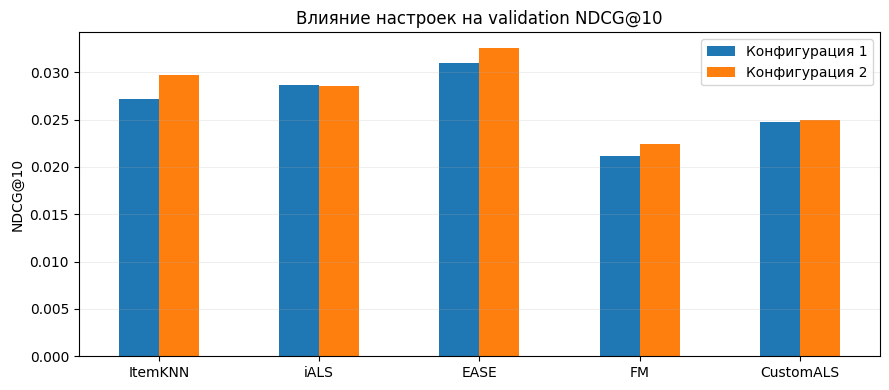

In [31]:
ax = comparison.plot.bar(figsize=(9, 4), rot=0)
ax.set(title='Влияние настроек на validation NDCG@10', xlabel='', ylabel='NDCG@10')
ax.grid(axis='y', alpha=.2)

plt.tight_layout()
plt.show()

## 5. Финальное сравнение
Настройки выбраны. Заново обучаем пять моделей на 1–25 октября и оцениваем на test (26–31 октября). Критерий релевантности, пользователи и кандидаты общие. По test ничего не подбираем.

In [32]:
history = events[events.event_time < VALID_END].copy()
test = events[events.event_time >= VALID_END].copy()

final_mats = matrices(history, shape, VALID_END)
test_truth = make_truth(test, final_mats['counts'])
final_examples = training_examples(final_mats, seed=SEED)

print('Test событий:', len(test), '; оцениваемых пользователей:', len(test_truth))
assert history.event_time.max() < test.event_time.min()

Test событий: 63759 ; оцениваемых пользователей: 2059


In [33]:
rows = []
user_results = []

In [34]:
for name, params in selected.items():
    model = fit_model(name, params, history, final_mats, final_examples)
    scores = evaluate(model, test_truth, final_mats['counts'])
    rows.append({'Модель': name, 'Параметры': params, **scores.mean().to_dict()})
    user_results.append(scores.assign(Модель=name))
    del model

In [35]:
results = pd.DataFrame(rows).set_index('Модель')
display(results)

,Параметры,NDCG@10,Recall@10
Модель,,,
ItemKNN,"{'neighbors': 100, 'shrinkage': 50.0}",0.030328,0.037812
iALS,"{'factors': 24, 'regularization': 1.0}",0.032114,0.038658
EASE,{'regularization': 300.0},0.036391,0.046606
FM,"{'factors': 24, 'regularization': 0.001}",0.028897,0.035216
CustomALS,"{'factors': 40, 'regularization': 10.0}",0.028686,0.033096


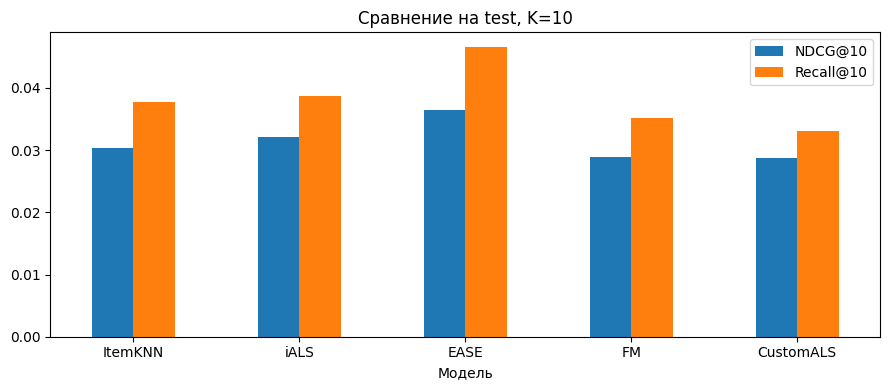

In [36]:
results[['NDCG@10', 'Recall@10']].plot.bar(figsize=(9, 4), rot=0)
plt.title('Сравнение на test, K=10')
plt.tight_layout()
plt.show()

### Кому модели рекомендуют лучше

Средняя метрика может скрывать разницу между пользователями. Сравним модели по числу разных товаров в истории до test: 1–20, 21–50 и больше 50. История включает все типы действий, как и правило исключения известных товаров. Границы фиксированы; для всех моделей пользователи и кандидаты внутри группы одинаковы.

На подписях указано число оцениваемых пользователей. Это диагностика уже выбранных моделей: параметры по этим результатам не меняем. Различия между группами не доказывают причинный эффект длины истории; сравнение не включает новых пользователей.

In [37]:
per_user = pd.concat(user_results)
history_size = final_mats['counts'].getnnz(axis=1)
groups = ['1–20', '21–50', '>50']

per_user['История'] = pd.cut(history_size[per_user.index], bins=[0, 20, 50, np.inf], labels=groups)
group_counts = per_user[per_user.Модель == 'ItemKNN'].groupby('История', observed=False).size()

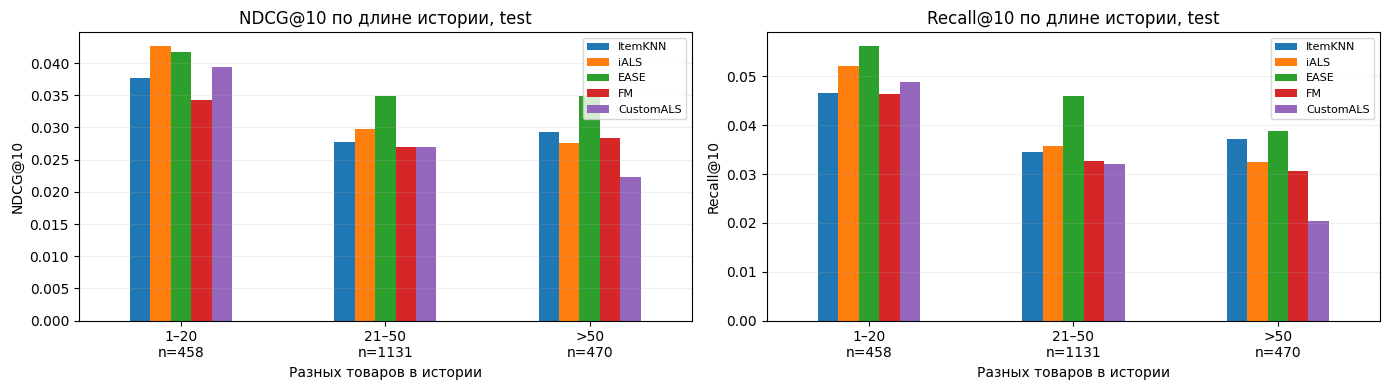

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for metric, ax in zip(['NDCG@10', 'Recall@10'], axes):
    quality = per_user.groupby(['История', 'Модель'], observed=False)[metric].mean().unstack()
    quality = quality.reindex(index=groups, columns=list(selected))
    quality.plot.bar(ax=ax, rot=0)

    ax.set(title=metric + ' по длине истории, test', xlabel='Разных товаров в истории', ylabel=metric)
    ax.set_xticklabels([f'{group}\nn={group_counts[group]}' for group in groups])
    ax.grid(axis='y', alpha=.2)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

iALS немного опережает EASE по NDCG@10 для истории из 1–20 товаров (458 пользователей), а EASE лидирует для 21–50 (1131 пользователь) и более 50 товаров (470 пользователей). По Recall@10 EASE лучше во всех трёх группах. Значимость различий не проверялась. Общий победитель не обязательно лучший для каждой группы.

В снимке train бренд известен примерно у 59% товаров, а категория и цена заполнены у всех. Это ограничивает доступную FM информацию о брендах, но не доказывает, что пропуски стали причиной её отставания. Для такого вывода нужен отдельный эксперимент с признаками.

## 6. Выводы

На этом разбиении EASE с регуляризацией 300 даёт лучший результат по обеим метрикам. Кастомный таргет не улучшил базовый iALS: эвристические веса событий и давность оказались менее полезны, чем бинарный сигнал. Это сравнение выбранных конфигураций, а не доказательство бесполезности такого подхода вообще.

FM с метаданными уступила EASE и iALS. Отдельно влияние метаданных здесь не измеряется, поэтому нельзя заключить, что именно они улучшили или ухудшили качество. Неизвестный бренд примерно у 40% исходных событий ограничивает информативность этого признака.

Ограничения: один месяц и магазин, отбор активных пользователей и популярных товаров, отсутствие оценки cold start, шумная релевантность корзины, ограниченный подбор. Снимок цены может устаревать; удаление из корзины не всегда означает отрицательное предпочтение. Повторные покупки исключены протоколом. Абсолютный Recall@10 невысок, поэтому результаты не означают готовность модели к внедрению.